{
  "help": "https://api.neso.energy/api/3/action/help_show?name=datastore_search",
  "success": true,
  "result": {
    "include_total": true,
    "resource_id": "7c0411cd-2714-4bb5-a408-adb065edf34d",
    "fields": [
      {
        "type": "int",
        "id": "_id"
      },
      {
        "info": {
          "comment": "",
          "description": "Date on which the forecast demand is occurring. This date is aligned with the GB timezone (BST/GMT).",
          "title": "Date",
          "type": "date",
          "example": "2021-11-16",
          "unit": ""
        },
        "type": "date",
        "id": "DATE"
      },
      {
        "info": {
          "comment": "",
          "description": "Time at which the forecast demand is occurring. This time uses the GB timezone (BST/GMT).",
          "title": "Clock Time",
          "type": "integer",
          "example": "130",
          "unit": ""
        },
        "type": "int4",
        "id": "CTIME"
      },
      {
        "info": {
          "comment": "",
          "description": "Datetime at which the demand is occurring. This is in GMT/UTC regardless of forecast date's GB timezone.",
          "title": "Datetime",
          "type": "datetime",
          "example": "2021-11-16T13:30:00",
          "unit": ""
        },
        "type": "timestamp",
        "id": "GDATETIME"
      },
      {
        "info": {
          "comment": "",
          "description": "The demand forecast for the specified datetime.",
          "title": "National Demand Forecast",
          "type": "integer",
          "example": "42000",
          "unit": "MW"
        },
        "type": "int4",
        "id": "NATIONALDEMAND"
      }
    ],
    "records_format": "objects",
    "records": [
      {
        "_id": 1,
        "DATE": "2026-09-19",
        "CTIME": 30,
        "GDATETIME": "2026-09-18T23:30:00",
        "NATIONALDEMAND": 19658
      },
      {
        "_id": 2,
        "DATE": "2026-09-19",
        "CTIME": 100,
        "GDATETIME": "2026-09-19T00:00:00",
        "NATIONALDEMAND": 19215
      },
      {
        "_id": 3,
        "DATE": "2026-09-19",
        "CTIME": 130,
        "GDATETIME": "2026-09-19T00:30:00",
        "NATIONALDEMAND": 18887
      },
      {
        "_id": 4,
        "DATE": "2026-09-19",
        "CTIME": 200,
        "GDATETIME": "2026-09-19T01:00:00",
        "NATIONALDEMAND": 18883
      },
      {
        "_id": 5,
        "DATE": "2026-09-19",
        "CTIME": 230,
        "GDATETIME": "2026-09-19T01:30:00",
        "NATIONALDEMAND": 18357
      }
    ],
    "limit": 5,
    "_links": {
      "start": "/api/3/action/datastore_search?limit=5&resource_id=7c0411cd-2714-4bb5-a408-adb065edf34d",
      "next": "/api/3/action/datastore_search?offset=5&limit=5&resource_id=7c0411cd-2714-4bb5-a408-adb065edf34d"
    },
    "total": 624
  }
}

In [2]:
import httpx
import pandas as pd
import matplotlib.pyplot as plt

API_URL = "https://api.neso.energy/api/3/action/datastore_search"
RESOURCE_ID = "7c0411cd-2714-4bb5-a408-adb065edf34d"


In [3]:
# 1. Fetch the data. `params` becomes ?resource_id=...&limit=100 on the URL.
response = httpx.get(API_URL, params={"resource_id": RESOURCE_ID, "limit": 10000})
payload = response.json()
records = payload["result"]["records"]

# 2. Look at one row to see what fields exist
print("First record:", records[0])

print("\nField descriptions:")
for field in payload["result"]["fields"]:
    field_id = field["id"]
    info = field.get("info", {})
    title = info.get("title", "")
    description = info.get("description", "")
    unit = info.get("unit", "")
    field_type = field.get("type", "")
    print(f"  {field_id} ({title}): {description} [{field_type}] [{unit}]")

# 3. Put it all in a DataFrame - a table, like a spreadsheet
df = pd.DataFrame(records)
print(f"\nShape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 rows:")
print(df.head())

First record: {'_id': 1, 'DATE': '2026-09-19', 'CTIME': 30, 'GDATETIME': '2026-09-18T23:30:00', 'NATIONALDEMAND': 19658}

Field descriptions:
  _id ():  [int] []
  DATE (Date): Date on which the forecast demand is occurring. This date is aligned with the GB timezone (BST/GMT). [date] []
  CTIME (Clock Time): Time at which the forecast demand is occurring. This time uses the GB timezone (BST/GMT). [int4] []
  GDATETIME (Datetime): Datetime at which the demand is occurring. This is in GMT/UTC regardless of forecast date's GB timezone. [timestamp] []
  NATIONALDEMAND (National Demand Forecast): The demand forecast for the specified datetime. [int4] [MW]

Shape: 624 rows, 5 columns

First 5 rows:
   _id        DATE  CTIME            GDATETIME  NATIONALDEMAND
0    1  2026-09-19     30  2026-09-18T23:30:00           19658
1    2  2026-09-19    100  2026-09-19T00:00:00           19215
2    3  2026-09-19    130  2026-09-19T00:30:00           18887
3    4  2026-09-19    200  2026-09-19T01:00:00

In [4]:
df.columns

Index(['_id', 'DATE', 'CTIME', 'GDATETIME', 'NATIONALDEMAND'], dtype='str')

In [5]:
df.describe()

,_id,CTIME,NATIONALDEMAND
count,624.000000,624.000000,624.000000
mean,312.500000,1215.000000,24331.240385
std,180.277564,693.658966,4075.712553
min,1.000000,30.000000,15825.000000
25%,156.750000,622.500000,20897.500000
50%,312.500000,1215.000000,24648.500000
75%,468.250000,1807.500000,27457.250000
max,624.000000,2400.000000,32698.000000


In [6]:
# 4. Convert GDATETIME to an actual datetime, sort chronologically
df["GDATETIME"] = pd.to_datetime(df["GDATETIME"])
df = df.sort_values("GDATETIME")


Saved chart to national_demand_forecast.png


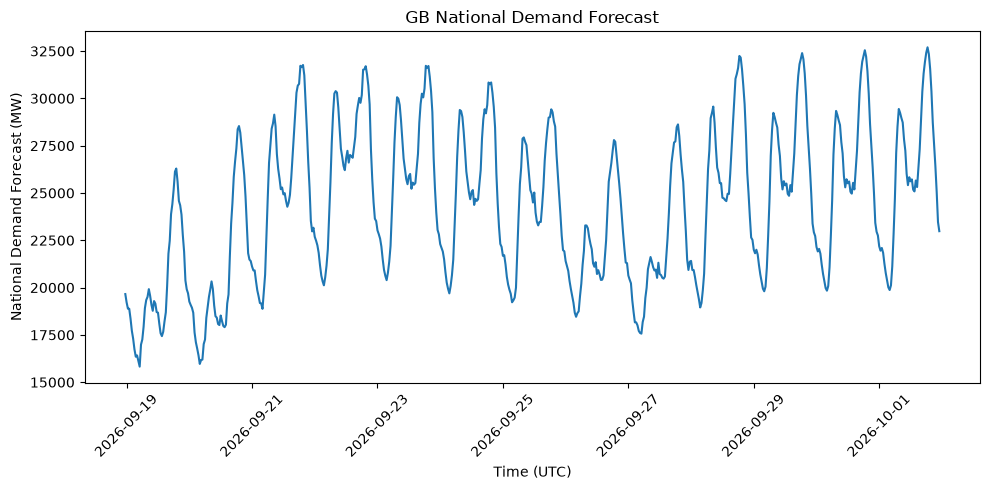

In [7]:
# 5. Plot national demand over time
plt.figure(figsize=(10, 5))
plt.plot(df["GDATETIME"], df["NATIONALDEMAND"])
plt.xlabel("Time (UTC)")
plt.ylabel("National Demand Forecast (MW)")
plt.title("GB National Demand Forecast")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("national_demand_forecast.png")
print("\nSaved chart to national_demand_forecast.png")